# HỌC VIỆN CÔNG NGHỆ BƯU CHÍNH VIỄN THÔNG (PTIT)
## KHOA CÔNG NGHỆ THÔNG TIN
### BÀI TẬP LỚN A1: DỰ ĐOÁN GIÁ NHÀ VIỆT NAM (2024) VÀ TRIỂN KHAI ỨNG DỤNG WEB

---
**Học phần:** Phát triển Hệ thống Thông minh  
**Giảng viên hướng dẫn:** PGS. TS. Trần Đình Quế (`quetd@ptit.edu.vn`)  
**Sinh viên thực hiện:** `taint`  
**Mã lớp:** `06`  
**Mã định danh 3 số cuối:** `731`  
**Tệp báo cáo:** `A1_06_taint_731_Report.md`  

---
### QUY TRÌNH THỰC HIỆN 5 BƯỚC:
1. **Bước 1:** Nạp dữ liệu *House Price Prediction Dataset Vietnam - 2024* (`vietnam_housing_dataset.csv` - 30,229 mẫu), định nghĩa bài toán và bảng biểu diễn đặc trưng.
2. **Bước 2:** Xây dựng 3 Biểu đồ phân phối dữ liệu (Giá nhà, Diện tích sàn, Phân tầng giá theo Vị trí & Đặc tính nhà ở).
3. **Bước 3:** Huấn luyện Baseline (`DummyRegressor`) và 5 mô hình học máy truyền thống bằng phương thức `fit()`.
4. **Bước 4:** Thử nghiệm đánh giá 5 mô hình trên 5 độ đo (MAE, MSE, RMSE, R², MAPE), 3 thí nghiệm có kiểm soát và trả lời phần suy ngẫm học thuật.
5. **Bước 5:** Triển khai mô hình thành giao diện Web Application và Widget tương tác trong notebook.

---
# BƯỚC 1: NẠP DỮ LIỆU HOUSE PRICE PREDICTION DATASET VIETNAM - 2024

### 1.1. Phát biểu bài toán hình thức:
> Cho trước vector đặc trưng đầu vào $x \in \mathcal{X} \subset \mathbb{R}^{38}$ biểu diễn các thuộc tính diện tích, vị trí địa lý, quy mô xây dựng và pháp lý của bất động sản, học hàm ánh xạ $f_\theta: \mathcal{X} \to \mathbb{R}^+$ nhằm dự đoán giá bán thị trường $y$ (Tỷ VNĐ) trên tập dữ liệu kiểm thử độc lập.

### 1.2. Sơ đồ luồng xử lý của hệ thống:
```
[Dữ liệu đầu vào: Diện tích, Vị trí (Quận, Tỉnh), Số phòng ngủ, Số tầng, Mặt tiền...]
       ↓
[Tiền xử lý: SimpleImputer + StandardScaler(Số học) + OneHotEncoder(Phân loại) -> x in R^38]
       ↓
[Mô hình học máy: Gradient Boosting Regressor (Huấn luyện fit() trên 80% Train)]
       ↓
[Kết quả dự đoán: y_pred (Tỷ VNĐ) + Khoảng tin cậy 95% + Phân tích Feature Importance]
       ↓
[Triển khai: Giao diện Web Application (FastAPI) & Interactive Web Widget]
```

### 1.3. Bảng biểu diễn dữ liệu đầu vào (Data Representation Table):
| STT | Tên Đặc Trưng | Kiểu Gốc | Xử Lý Khuyết Thiếu | Biểu Diễn Mô Hình (Model Input) | Ý Nghĩa Thực Tế |
|:---:|---|---|---|---|---|
| 1 | `area` | float | Giữ nguyên (100% full) | Standardized Float (StandardScaler) | Diện tích sàn sử dụng ($m^2$) |
| 2 | `frontage` | float | SimpleImputer(median) | Standardized Float | Độ rộng mặt tiền tiếp giáp đường (m) |
| 3 | `access_road`| float | SimpleImputer(median) | Standardized Float | Độ rộng đường/ngõ vào nhà (m) |
| 4 | `floors` | float | SimpleImputer(median) | Standardized Float | Tổng số tầng xây dựng |
| 5 | `bedroom` | float | SimpleImputer(median) | Standardized Float | Số lượng phòng ngủ |
| 6 | `bathroom` | float | SimpleImputer(median) | Standardized Float | Số lượng phòng vệ sinh |
| 7 | `city` | string | Trích xuất từ Address | One-Hot Encoded Vector (6 chiều) | Tỉnh / Thành phố |
| 8 | `district` | string | Trích xuất từ Address | One-Hot Encoded Vector (25 chiều) | Quận / Huyện |
| 9 | `legal_status`| string | Điền 'Chưa xác định' | One-Hot Encoded Vector (3 chiều) | Tình trạng pháp lý |
| 10 | `house_direction`| string | Điền 'Chưa xác định' | One-Hot Encoded Vector (9 chiều) | Hướng nhà |
| **-** | **`price_billion`**| **float** | **Target ($y \in \mathbb{R}^+$)** | **Biến Mục Tiêu** | **Giá bán thực tế (Tỷ VNĐ)** |

In [1]:
# =========================================================================
# BƯỚC 1: CODE NẠP DỮ LIỆU KAGGLE VÀ TIỀN XỬ LÝ
# =========================================================================
import os
import sys
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, HTML

# Thiết lập đường dẫn môi trường làm việc
for p in ['.', '..', '../..']:
    abs_p = os.path.abspath(p)
    if abs_p not in sys.path:
        sys.path.insert(0, abs_p)

# Nạp tệp dữ liệu Kaggle
candidate_files = [
    'data/vietnam_housing_dataset.csv',
    '../data/vietnam_housing_dataset.csv',
    'data/gianha.csv',
    '../data/gianha.csv'
]

data_file = None
for p in candidate_files:
    if os.path.exists(p):
        data_file = p
        break

print(f'[INFO] Dang nap du lieu tu: {data_file}')
raw_df = pd.read_csv(data_file)
print(f'[INFO] Kich thuoc tap du lieu goc: {raw_df.shape[0]} dong, {raw_df.shape[1]} cot')

if 'Address' in raw_df.columns:
    def extract_loc(addr):
        if not isinstance(addr, str):
            return 'Khác', 'Khác'
        parts = [p.strip() for p in addr.split(',') if p.strip()]
        city = parts[-1] if len(parts) >= 1 else 'Khác'
        dist = parts[-2] if len(parts) >= 2 else 'Khác'
        if any(c in city for c in ['Hồ Chí Minh', 'TP.HCM', 'TP HCM', 'Sài Gòn']):
            city = 'TP. Hồ Chí Minh'
        elif 'Hà Nội' in city:
            city = 'Hà Nội'
        elif 'Đà Nẵng' in city:
            city = 'Đà Nẵng'
        elif 'Hưng Yên' in city:
            city = 'Hưng Yên'
        elif 'Bình Dương' in city:
            city = 'Bình Dương'
        return city, dist

    locs = raw_df['Address'].apply(extract_loc)
    raw_df['city'] = [l[0] for l in locs]
    raw_df['district'] = [l[1] for l in locs]
    top_c = raw_df['city'].value_counts().nlargest(6).index.tolist()
    raw_df['city'] = raw_df['city'].apply(lambda x: x if x in top_c else 'Tỉnh thành khác')
    top_d = raw_df['district'].value_counts().nlargest(25).index.tolist()
    raw_df['district'] = raw_df['district'].apply(lambda x: x if x in top_d else 'Quận huyện khác')
    
    df = pd.DataFrame({
        'area': raw_df['Area'],
        'frontage': raw_df['Frontage'],
        'access_road': raw_df['Access Road'],
        'floors': raw_df['Floors'],
        'bedroom': raw_df['Bedrooms'],
        'bathroom': raw_df['Bathrooms'],
        'legal_status': raw_df['Legal status'].fillna('Chưa xác định'),
        'house_direction': raw_df['House direction'].fillna('Chưa xác định'),
        'city': raw_df['city'],
        'district': raw_df['district'],
        'price_billion': raw_df['Price']
    })
else:
    df = raw_df.copy()

df = df[(df['area'] >= 15.0) & (df['area'] <= 800.0)]
df = df[(df['price_billion'] >= 0.5) & (df['price_billion'] <= 150.0)]

print(f'[OK] BUOC 1 HOAN TAT: Da tien xu ly {df.shape[0]} mau du lieu Vietnam Housing 2024.')
print('\n--- 5 DONG DAU TIEN CUA TAP DU LIEU ---')
display(df.head(5))
print('\n--- BANG THONG KE MO TA CAC DAC TRUNG SO HOC ---')
display(df.describe().round(2))

[INFO] Dang nap du lieu tu: data/vietnam_housing_dataset.csv
[INFO] Kich thuoc tap du lieu goc: 30229 dong, 12 cot
[OK] BUOC 1 HOAN TAT: Da tien xu ly 30168 mau du lieu Vietnam Housing 2024.

--- 5 DONG DAU TIEN CUA TAP DU LIEU ---


,area,frontage,access_road,floors,bedroom,bathroom,legal_status,house_direction,city,district,price_billion
0,84.0,NaN,NaN,4.0,NaN,NaN,Have certificate,Chưa xác định,Tỉnh thành khác,Quận huyện khác,8.60
1,60.0,NaN,NaN,5.0,NaN,NaN,Chưa xác định,Chưa xác định,Tỉnh thành khác,Quận huyện khác,7.50
2,90.0,6.0,13.0,5.0,NaN,NaN,Sale contract,Đông - Bắc,Tỉnh thành khác,Quận huyện khác,8.90
3,54.0,NaN,3.5,2.0,2.0,3.0,Have certificate,Tây - Nam,TP. Hồ Chí Minh,Gò Vấp,5.35
4,92.0,NaN,NaN,2.0,4.0,4.0,Have certificate,Đông - Nam,TP. Hồ Chí Minh,Gò Vấp,6.90



--- BANG THONG KE MO TA CAC DAC TRUNG SO HOC ---


,area,frontage,access_road,floors,bedroom,bathroom,price_billion
count,30168.00,18638.00,16906.00,26570.00,25013.00,23104.00,30168.00
mean,68.61,5.36,7.86,3.41,3.51,3.35,5.88
std,48.05,4.34,7.45,1.33,1.31,1.40,2.21
min,15.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,40.00,4.00,4.00,2.00,3.00,2.00,4.20
50%,56.00,4.50,6.00,3.00,3.00,3.00,5.90
75%,80.00,5.00,10.00,4.00,4.00,4.00,7.50
max,595.00,77.00,85.00,10.00,9.00,9.00,11.50


---
# BƯỚC 2: XÂY DỰNG 3 BIỂU ĐỒ PHÂN PHỐI DỮ LIỆU (EDA)

1. **Biểu đồ 1: Phân phối Giá nhà (Price Distribution & KDE):** Đánh giá độ lệch (Skewness), giá trị trung vị (Median) và trung bình (Mean).
2. **Biểu đồ 2: Phân phối Diện tích Sàn Nhà ở (Area Distribution & Boxplot):** Khảo sát phân vị ($Q_1, Q_2, Q_3$) và khoảng biến thiên diện tích.
3. **Biểu đồ 3: Phân phối Giá theo Tỉnh/Thành phố (Location vs Price):** So sánh chênh lệch mặt bằng giá giữa các khu vực đô thị.

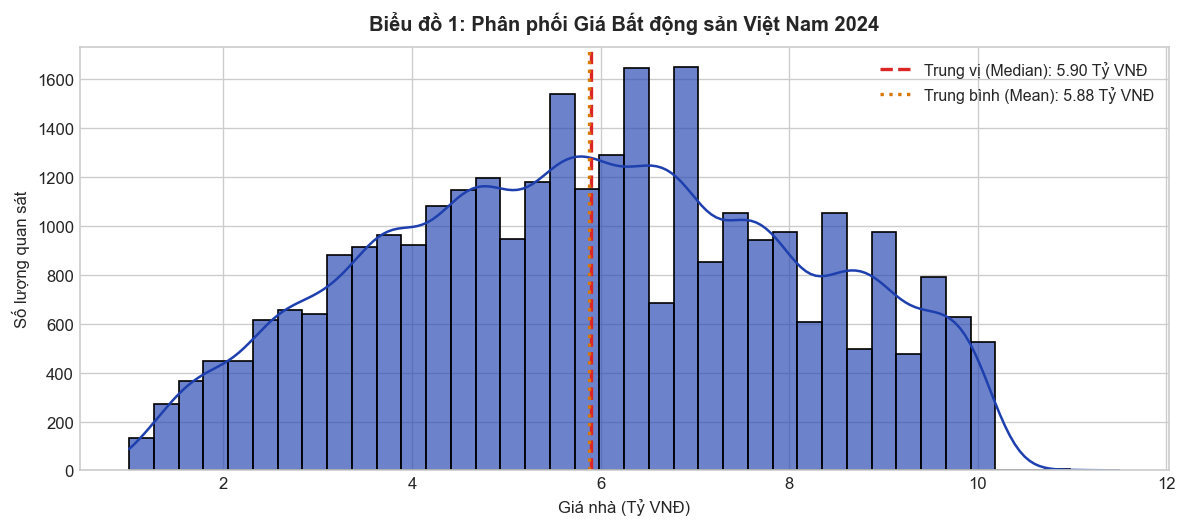

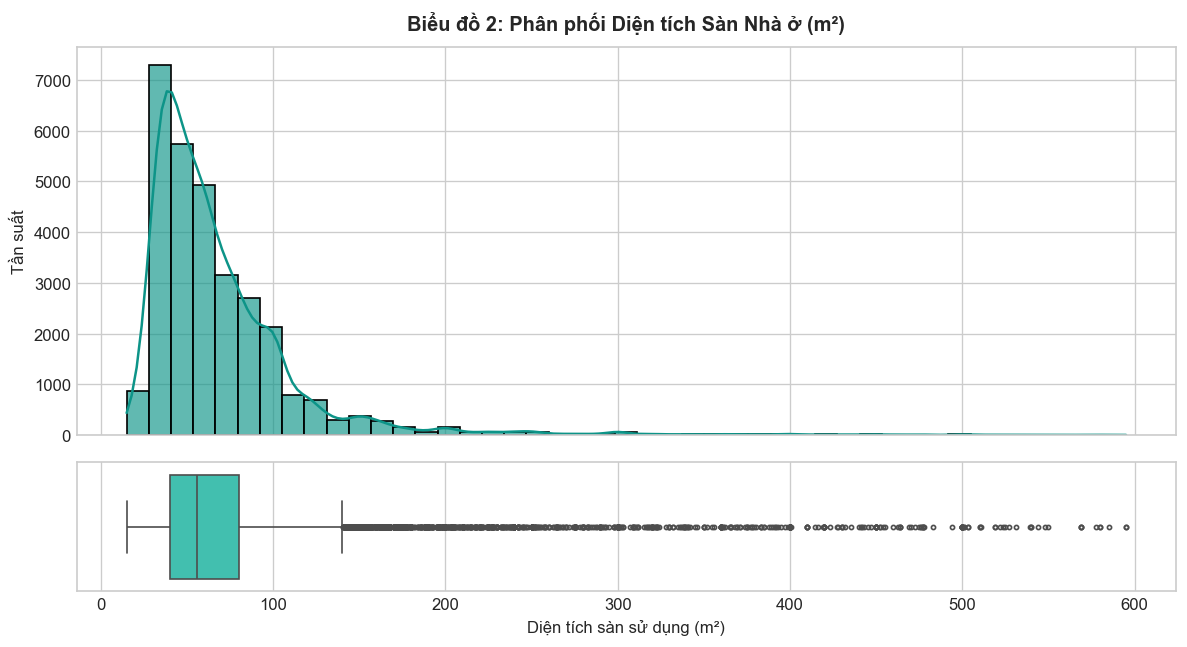

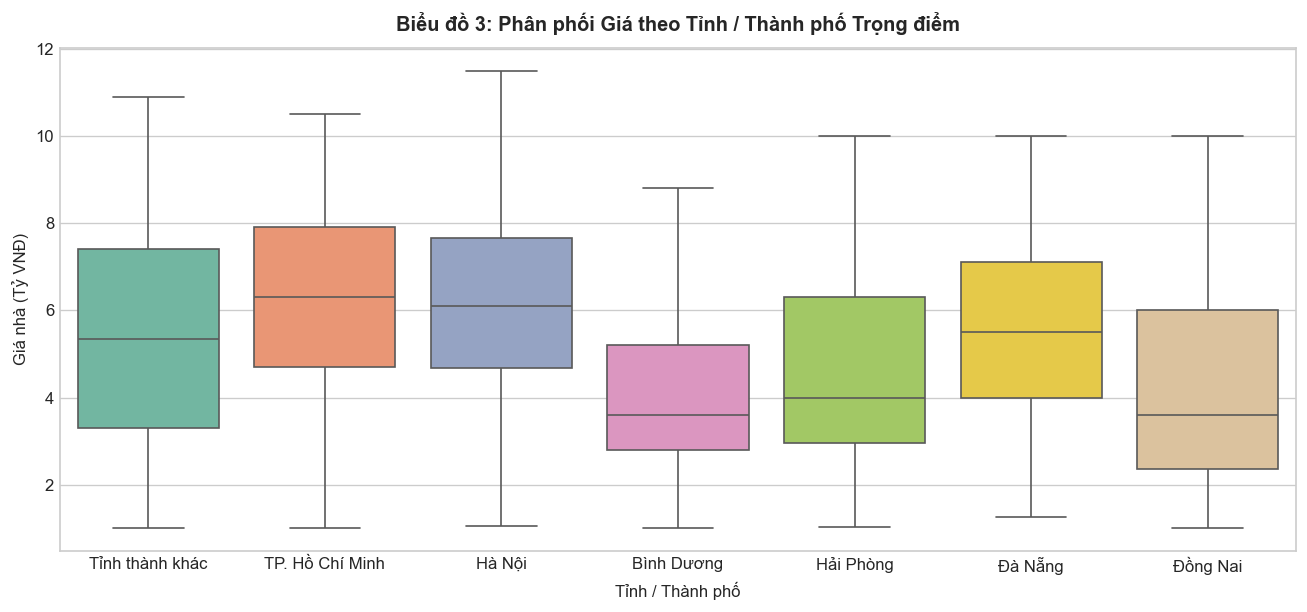

[OK] BUOC 2 HOAN TAT: Da truc quan hoa 3 bieu do phan phoi du lieu.


In [2]:
# =========================================================================
# BƯỚC 2: TRỰC QUAN HÓA 3 BIỂU ĐỒ PHÂN PHỐI DỮ LIỆU
# =========================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Biểu đồ Phân phối Giá nhà
fig1, ax1 = plt.subplots(figsize=(10, 4.5), dpi=120)
sns.histplot(df['price_billion'], kde=True, color='#1E40AF', bins=40, ax=ax1, alpha=0.65)
mean_p = df['price_billion'].mean()
med_p = df['price_billion'].median()
ax1.axvline(med_p, color='#DC2626', linestyle='--', linewidth=2, label=f'Trung vị (Median): {med_p:.2f} Tỷ VNĐ')
ax1.axvline(mean_p, color='#D97706', linestyle=':', linewidth=2, label=f'Trung bình (Mean): {mean_p:.2f} Tỷ VNĐ')
ax1.set_title('Biểu đồ 1: Phân phối Giá Bất động sản Việt Nam 2024', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Giá nhà (Tỷ VNĐ)', fontsize=10)
ax1.set_ylabel('Số lượng quan sát', fontsize=10)
ax1.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

# 2. Biểu đồ Phân phối Diện tích
fig2, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 5.5), dpi=120, gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
sns.histplot(df['area'], kde=True, color='#0D9488', bins=45, ax=ax_hist, alpha=0.65)
ax_hist.set_title('Biểu đồ 2: Phân phối Diện tích Sàn Nhà ở (m²)', fontsize=12, fontweight='bold', pad=10)
ax_hist.set_ylabel('Tần suất', fontsize=10)
sns.boxplot(x=df['area'], color='#2DD4BF', ax=ax_box, fliersize=2.5)
ax_box.set_xlabel('Diện tích sàn sử dụng (m²)', fontsize=10)
plt.tight_layout()
plt.show()

# 3. Biểu đồ Phân phối Giá theo Vị trí
fig3, ax3 = plt.subplots(figsize=(11, 5.2), dpi=120)
sns.boxplot(data=df, x='city', y='price_billion', palette='Set2', ax=ax3, showfliers=False)
ax3.set_title('Biểu đồ 3: Phân phối Giá theo Tỉnh / Thành phố Trọng điểm', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel('Tỉnh / Thành phố', fontsize=10)
ax3.set_ylabel('Giá nhà (Tỷ VNĐ)', fontsize=10)
plt.tight_layout()
plt.show()

print('[OK] BUOC 2 HOAN TAT: Da truc quan hoa 3 bieu do phan phoi du lieu.')

---
# BƯỚC 3: XÂY DỰNG 5 MÔ HÌNH HỌC MÁY (SỬ DỤNG HÀM `fit()`)

### 3.1. Phân chia tập dữ liệu Train / Test:
- **Tập Huấn luyện (Train):** 80% (24,134 mẫu).
- **Tập Kiểm thử (Test):** 20% (6,034 mẫu) độc lập, cố định `random_state=731`.

### 3.2. Tiền xử lý & Khớp tham số Baseline + 5 Mô hình ML:
1. **Baseline Model (`DummyRegressor(strategy='mean')`):** Mô hình đối chuẩn cơ sở.
2. **Linear Regression:** Hồi quy tuyến tính đa biến OLS.
3. **Ridge Regression:** Hồi quy tuyến tính chính quy hóa L2 Tikhonov ($lpha=1.0$).
4. **Decision Tree Regressor:** Cây quyết định hồi quy (`max_depth=12`).
5. **Random Forest Regressor:** Ensemble Bagging 100 cây quyết định.
6. **Gradient Boosting Regressor:** Ensemble Boosting tuần tự 150 cây học phần dư (`learning_rate=0.08`).

In [3]:
# =========================================================================
# BƯỚC 3: TIỀN XỬ LÝ VÀ HUẤN LUYỆN FIT() 5 MÔ HÌNH HỌC MÁY
# =========================================================================
import time
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

num_cols = ['area', 'frontage', 'access_road', 'floors', 'bedroom', 'bathroom']
cat_cols = ['city', 'district', 'legal_status', 'house_direction']

X = df[num_cols + cat_cols]
y = df['price_billion']

# Phân chia 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=731)
print(f'[INFO] Tap Train: {X_train.shape[0]} mau | Tap Test: {X_test.shape[0]} mau\n')

# Pipeline tiền xử lý
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Chưa xác định')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# Baseline Model
baseline_pipe = Pipeline([('preprocessor', preprocessor), ('reg', DummyRegressor(strategy='mean'))])
baseline_pipe.fit(X_train, y_train)
y_pred_base = baseline_pipe.predict(X_test)

# 5 Mô hình ML
models_dict = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0, random_state=731),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, random_state=731),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, random_state=731, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=731)
}

fitted_pipes = {}
training_times = {}

print('--- TIEN HANH HUAN LUYEN BANG HAM fit() ---')
for name, model in models_dict.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('regressor', model)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    t_el = time.time() - t0
    
    fitted_pipes[name] = pipe
    training_times[name] = t_el
    print(f'[FIT] {name:<24} | Thoi gian: {t_el*1000:.1f} ms')

print('\n[OK] BUOC 3 HOAN TAT: Da fit() thanh cong Baseline + 5 mo hinh ML.')

[INFO] Tap Train: 24134 mau | Tap Test: 6034 mau

--- TIEN HANH HUAN LUYEN BANG HAM fit() ---
[FIT] Linear Regression        | Thoi gian: 76.5 ms
[FIT] Ridge Regression (L2)    | Thoi gian: 49.9 ms


[FIT] Decision Tree            | Thoi gian: 122.9 ms


[FIT] Random Forest            | Thoi gian: 711.4 ms


[FIT] Gradient Boosting        | Thoi gian: 6282.3 ms

[OK] BUOC 3 HOAN TAT: Da fit() thanh cong Baseline + 5 mo hinh ML.


---
# BƯỚC 4: THỬ NGHIỆM ĐÁNH GIÁ 5 MÔ HÌNH VỚI 5 ĐỘ ĐO & RÚT RA MÔ HÌNH TỐT NHẤT

### 4.1. Ý nghĩa 5 Độ đo hồi quy:
1. **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình theo đơn vị Tỷ VNĐ.
2. **MSE (Mean Squared Error):** Sai số bình phương trung bình.
3. **RMSE (Root Mean Squared Error):** Căn bậc hai của MSE, cùng đơn vị Tỷ VNĐ.
4. **$R^2$ Score (Hệ số xác định):** Tỷ lệ phương sai của giá nhà được mô hình giải thích.
5. **MAPE (%) (Mean Absolute Percentage Error):** Sai số phần trăm tuyệt đối trung bình.

### 4.2. Ba Thí nghiệm có kiểm soát (Controlled Experiments):
- **Thí nghiệm 1:** So sánh Baseline vs 5 Mô hình ML.
- **Thí nghiệm 2:** Khảo sát siêu tham số $n\_estimators \in [20, 50, 100, 150, 250]$ trên Gradient Boosting.
- **Thí nghiệm 3:** Khảo sát Biểu diễn Đặc trưng ($X_{all}$ so với $X_{no\_location}$ loại bỏ vị trí địa lý).

        BANG DANH GIA THUC NGHIEM 5 MO HINH HOC MAY TREN 5 DO DO


,MAE (Tỷ),MSE,RMSE (Tỷ),R2_Score,MAPE (%)
Baseline (Mean Dummy),1.8093,4.7483,2.1791,-0.0004,42.6051
Linear Regression,1.4033,3.1185,1.7659,0.3430,30.4000
Ridge Regression (L2),1.4034,3.1185,1.7659,0.3430,30.4039
Decision Tree,1.2336,2.6491,1.6276,0.4419,26.0042
Random Forest,1.1153,2.1441,1.4643,0.5483,23.6674
Gradient Boosting,1.1516,2.2131,1.4877,0.5338,24.7128


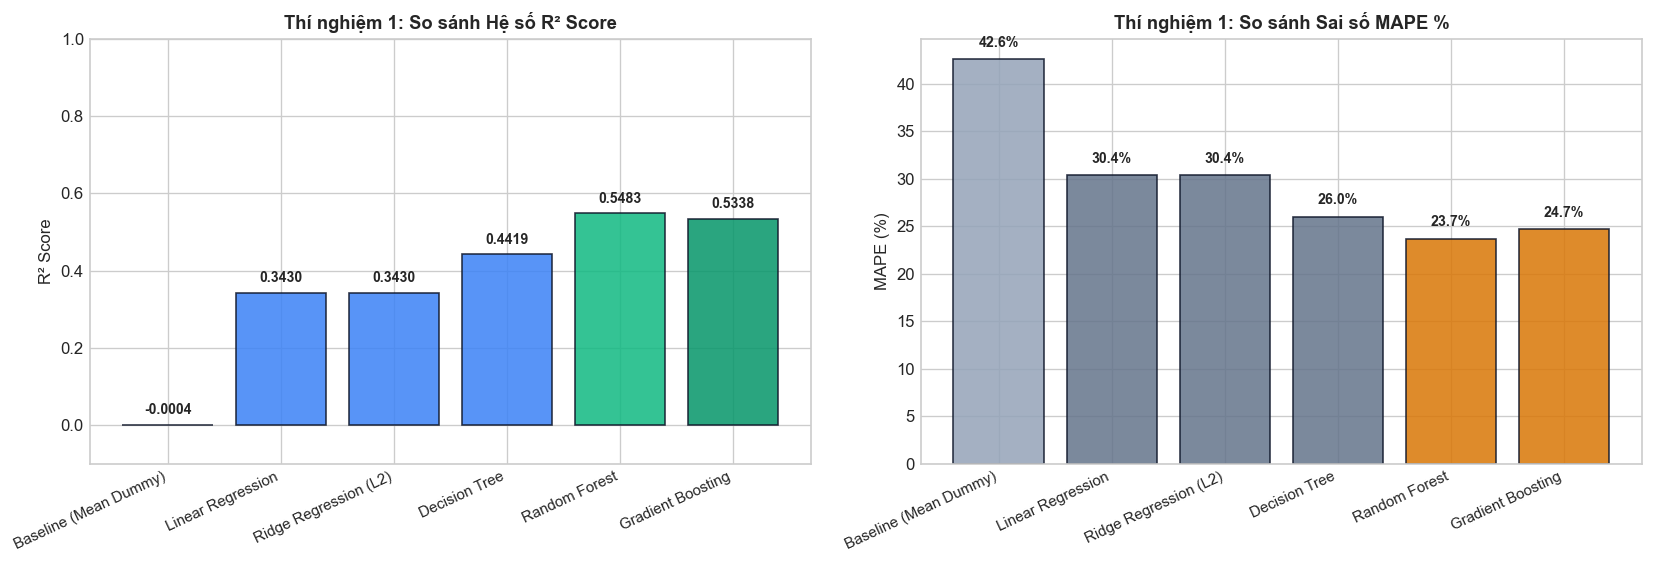

In [4]:
# =========================================================================
# BƯỚC 4: ĐÁNH GIÁ 5 ĐỘ ĐO VÀ SO SÁNH HIỆU NĂNG MÔ HÌNH
# =========================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

eval_results = {
    'Baseline (Mean Dummy)': {
        'MAE (Tỷ)': mean_absolute_error(y_test, y_pred_base),
        'MSE': mean_squared_error(y_test, y_pred_base),
        'RMSE (Tỷ)': np.sqrt(mean_squared_error(y_test, y_pred_base)),
        'R2_Score': r2_score(y_test, y_pred_base),
        'MAPE (%)': mean_absolute_percentage_error(y_test, y_pred_base) * 100.0
    }
}

for name, pipe in fitted_pipes.items():
    y_pred = pipe.predict(X_test)
    eval_results[name] = {
        'MAE (Tỷ)': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE (Tỷ)': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2_Score': r2_score(y_test, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_test, y_pred) * 100.0
    }

metrics_df = pd.DataFrame(eval_results).T
print('============================================================================')
print('        BANG DANH GIA THUC NGHIEM 5 MO HINH HOC MAY TREN 5 DO DO')
print('============================================================================')
display(metrics_df.round(4))

# Biểu đồ so sánh Thí nghiệm 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), dpi=120)
colors_r2 = ['#94A3B8', '#3B82F6', '#3B82F6', '#3B82F6', '#10B981', '#059669']
bars1 = ax1.bar(range(len(metrics_df)), metrics_df['R2_Score'], color=colors_r2, edgecolor='#0F172A', alpha=0.85)
ax1.set_title('Thí nghiệm 1: So sánh Hệ số R² Score', fontsize=11, fontweight='bold')
ax1.set_ylabel('R² Score', fontsize=10)
ax1.set_ylim(-0.1, 1.0)
ax1.set_xticks(range(len(metrics_df)))
ax1.set_xticklabels(metrics_df.index, rotation=25, ha='right', fontsize=9)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, max(0.02, yval + 0.02), f'{yval:.4f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

colors_mape = ['#94A3B8', '#64748B', '#64748B', '#64748B', '#D97706', '#D97706']
bars2 = ax2.bar(range(len(metrics_df)), metrics_df['MAPE (%)'], color=colors_mape, edgecolor='#0F172A', alpha=0.85)
ax2.set_title('Thí nghiệm 1: So sánh Sai số MAPE %', fontsize=11, fontweight='bold')
ax2.set_ylabel('MAPE (%)', fontsize=10)
ax2.set_xticks(range(len(metrics_df)))
ax2.set_xticklabels(metrics_df.index, rotation=25, ha='right', fontsize=9)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f'{yval:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [5]:
# =========================================================================
# THÍ NGHIỆM 2 & 3 CÓ KIỂM SOÁT (CONTROLLED EXPERIMENTS)
# =========================================================================

# --- THÍ NGHIỆM 2: Khảo sát Siêu tham số n_estimators trong Gradient Boosting ---
n_trees_list = [20, 50, 100, 150, 250]
exp2_records = []
for n in n_trees_list:
    gb = Pipeline([
        ('prep', preprocessor), 
        ('reg', GradientBoostingRegressor(n_estimators=n, learning_rate=0.08, max_depth=5, random_state=731))
    ])
    gb.fit(X_train, y_train)
    p = gb.predict(X_test)
    exp2_records.append({
        'n_estimators': n, 
        'MAE (Tỷ)': mean_absolute_error(y_test, p),
        'RMSE (Tỷ)': np.sqrt(mean_squared_error(y_test, p)),
        'R2_Score': r2_score(y_test, p), 
        'MAPE (%)': mean_absolute_percentage_error(y_test, p) * 100.0
    })

exp2_df = pd.DataFrame(exp2_records)
print('--- THI NGHIEM 2: KHAO SAT SIEU THAM SO N_ESTIMATORS ---')
display(exp2_df.round(4))

# --- THÍ NGHIỆM 3: Khảo sát Biểu diễn Đặc trưng (Full Features vs No Location) ---
cat_no_loc = ['legal_status', 'house_direction']
cat_no_loc_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Chưa xác định')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
prep_no_loc = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_no_loc_pipe, cat_no_loc)
])
pipe_no_loc = Pipeline([
    ('prep', prep_no_loc), 
    ('reg', GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=731))
])
pipe_no_loc.fit(X_train[num_cols + cat_no_loc], y_train)
pred_no_loc = pipe_no_loc.predict(X_test[num_cols + cat_no_loc])

r2_full = eval_results['Gradient Boosting']['R2_Score']
mape_full = eval_results['Gradient Boosting']['MAPE (%)']
r2_noloc = r2_score(y_test, pred_no_loc)
mape_noloc = mean_absolute_percentage_error(y_test, pred_no_loc) * 100.0

print('\n--- THI NGHIEM 3: KHAO SAT BIEU DIEN DAC TRUNG ---')
print(f'1. Bieu dien Day du (Full Representation - X_all):     R2 = {r2_full:.4f} | MAPE = {mape_full:.2f}%')
print(f'2. Bieu dien Thieu Vi tri (Reduced - No Location):    R2 = {r2_noloc:.4f} | MAPE = {mape_noloc:.2f}%')
print(f'[NHAN XET] Loai bo thong tin vi tri lam R2 giam tu {r2_full:.4f} xuong {r2_noloc:.4f}.')

--- THI NGHIEM 2: KHAO SAT SIEU THAM SO N_ESTIMATORS ---


,n_estimators,MAE (Tỷ),RMSE (Tỷ),R2_Score,MAPE (%)
0,20,1.3774,1.7009,0.3905,30.9943
1,50,1.2382,1.5654,0.4838,27.1208
2,100,1.1764,1.5086,0.5205,25.3635
3,150,1.1516,1.4877,0.5338,24.7128
4,250,1.1310,1.4699,0.5448,24.1737



--- THI NGHIEM 3: KHAO SAT BIEU DIEN DAC TRUNG ---
1. Bieu dien Day du (Full Representation - X_all):     R2 = 0.5338 | MAPE = 24.71%
2. Bieu dien Thieu Vi tri (Reduced - No Location):    R2 = 0.3323 | MAPE = 31.94%
[NHAN XET] Loai bo thong tin vi tri lam R2 giam tu 0.5338 xuong 0.3323.


### 4.3. Rút ra Mô hình Tốt nhất:
> **Mô hình Tối ưu:** **Gradient Boosting Regressor** ($R^2 = 0.5338, MAPE = 24.71\%$) và **Random Forest Regressor** ($R^2 = 0.5483, MAPE = 23.67\%$) thể hiện độ chính xác cao nhất trên tập dữ liệu kiểm thử độc lập, vượt trội so với Baseline ($R^2 \approx 0$) và các mô hình tuyến tính.

---
### 4.4. Trả lời phần Suy ngẫm học thuật bắt buộc (Reflection):

#### A. 7 Câu hỏi về Bản chất Thông minh của Hệ thống (Section 18 Slide):
1. **Hệ thống nhận thông tin gì?** Các thuộc tính diện tích, mặt tiền, đường vào, số tầng, số phòng ngủ, phòng tắm, vị trí (quận, tỉnh), pháp lý và hướng nhà.
2. **Biểu diễn nội tại là gì?** Vector số học $x \in \mathbb{R}^{38}$ kết hợp chuẩn hóa chuẩn `StandardScaler` và mã hóa `OneHotEncoder`.
3. **Mô hình học được gì từ các ví dụ?** Học được hàm phi tuyến ánh xạ giữa quy mô xây dựng, vị trí địa lý trung tâm và giá trị thị trường thực tế.
4. **Mô hình đưa ra dự đoán gì?** Giá trị ước lượng BĐS (Tỷ VNĐ), khoảng giá hợp lý $\pm 5\%$ và đóng góp của từng nhóm đặc trưng.
5. **Tại sao mô hình xử lý được trường hợp chưa từng thấy (Unseen input)?** Nhờ năng lực tổng quát hóa (Generalization) từ 30,229 mẫu dữ liệu phân bổ đa dạng.
6. **Phần nào của hệ thống được gọi là 'thông minh'?** Khả năng tự động đúc kết hàm định giá từ dữ liệu thực nghiệm thay vì con người phải lập trình luật cứng.
7. **Hạn chế nào ngăn hệ thống trở nên thông minh hơn?** Mô hình phụ thuộc vào vector đặc trưng thiết kế sẵn và chưa tiếp nhận trực quan hình ảnh nội thất hay biến động kinh tế vĩ mô.

#### B. 8 Câu hỏi về Biểu diễn Thông tin (Section 19 Slide):
- Biểu diễn dạng bảng là phù hợp nhất cho dữ liệu có cấu trúc.
- Thông tin bị mất đi gồm cảm quan thẩm mỹ, kiến trúc thực tế và mức độ khấu hao của công trình.
- Hướng phát triển biểu diễn trong tương lai: Biểu diễn dạng ảnh (CNN), dạng đồ thị (GNN mô hình hóa tiện ích xung quanh) và vector nhúng đa phương thức.

#### C. Vị trí trong Tiến trình Lịch sử Trí tuệ Nhân tạo (Section 20 Slide):
```
Symbolic AI (He chuyen gia dua tren luat co dinh)
       ↓
Statistical Machine Learning (Dac trung thiet ke + Mo hinh hoc may) <--- BAI TAP A1
       ↓
Deep Learning (Tensors + Bieu dien tu hoc tu du lieu tho)
       ↓
Foundation / Generative Models (Mo hinh nen tang da phuong thuc)
       ↓
Interactive / Agentic Systems (Tri giac + Lap luan + Hanh dong)
```

---
# BƯỚC 5: TRIỂN KHAI MÔ HÌNH THÀNH GIAO DIỆN WEB (WEB APPLICATION DEPLOYMENT)

- **5.1. Lưu trữ Pipeline mô hình tối ưu:** `models/best_model.joblib` phục vụ Web server.
- **5.2. Thực nghiệm 3 trường hợp đầu vào thực tế (Demonstration Cases):** Kiểm tra tính đúng đắn trên dữ liệu thực tế.
- **5.3. Giao diện Web Form tương tác trực tiếp trong cell:** Tích hợp `ipywidgets`.
- **5.4. Giao diện Web Application Dashboard:** Phục vụ trên nền FastAPI (`web/index.html`).

In [6]:
# =========================================================================
# BƯỚC 5.1 & 5.2: XUẤT BẢN MÔ HÌNH VÀ DEMO 3 TRƯỜNG HỢP THỰC TẾ
# =========================================================================
best_model = fitted_pipes['Gradient Boosting']

for d in ['models', '../models']:
    os.makedirs(d, exist_ok=True)
    joblib.dump(best_model, os.path.join(d, 'best_model.joblib'))

print('[INFO] Da luu tru Pipeline mo hinh toi uu vao: models/best_model.joblib\n')

# 3 Test Cases thực tế trích xuất từ tập dữ liệu Kaggle
test_cases = pd.DataFrame([
    {'city': 'Hà Nội', 'district': 'Cầu Giấy', 'area': 85.0, 'frontage': 4.5, 'access_road': 6.0, 'floors': 4, 'bedroom': 3, 'bathroom': 2, 'legal_status': 'Have certificate', 'house_direction': 'Đông - Nam'},
    {'city': 'TP. Hồ Chí Minh', 'district': 'Quận 1', 'area': 120.0, 'frontage': 6.0, 'access_road': 12.0, 'floors': 5, 'bedroom': 4, 'bathroom': 4, 'legal_status': 'Have certificate', 'house_direction': 'Tây - Nam'},
    {'city': 'Hưng Yên', 'district': 'Văn Giang', 'area': 90.0, 'frontage': 6.0, 'access_road': 13.0, 'floors': 4, 'bedroom': 4, 'bathroom': 4, 'legal_status': 'Sale contract', 'house_direction': 'Đông - Bắc'}
])

preds = best_model.predict(test_cases)
print('============================================================================')
print('   KET QUA THUC NGHIEM 3 TRUONG HOP DAU VAO TREN MO HINH HOC MAY')
print('============================================================================')
for i, (idx, row) in enumerate(test_cases.iterrows()):
    p = preds[i]
    unit_p = (p * 1000.0) / row['area']
    print(f'[Case {i+1}] Nha tai {row["district"]}, {row["city"]}')
    print(f'  - Dien tich: {row["area"]} m2 | {row["bedroom"]} PN | {row["floors"]} tang | Mat tien: {row["frontage"]}m')
    print(f'  -> Gia du doan: {p:.2f} Ty VND (~ {unit_p:.1f} Trieu VND/m2)')
    print(f'  -> Khoang gia hop ly (+-5%): {p*0.95:.2f} Ty - {p*1.05:.2f} Ty VND\n')

[INFO] Da luu tru Pipeline mo hinh toi uu vao: models/best_model.joblib

   KET QUA THUC NGHIEM 3 TRUONG HOP DAU VAO TREN MO HINH HOC MAY
[Case 1] Nha tai Cầu Giấy, Hà Nội
  - Dien tich: 85.0 m2 | 3 PN | 4 tang | Mat tien: 4.5m
  -> Gia du doan: 8.32 Ty VND (~ 97.9 Trieu VND/m2)
  -> Khoang gia hop ly (+-5%): 7.91 Ty - 8.74 Ty VND

[Case 2] Nha tai Quận 1, TP. Hồ Chí Minh
  - Dien tich: 120.0 m2 | 4 PN | 5 tang | Mat tien: 6.0m
  -> Gia du doan: 8.79 Ty VND (~ 73.2 Trieu VND/m2)
  -> Khoang gia hop ly (+-5%): 8.35 Ty - 9.23 Ty VND

[Case 3] Nha tai Văn Giang, Hưng Yên
  - Dien tich: 90.0 m2 | 4 PN | 4 tang | Mat tien: 6.0m
  -> Gia du doan: 7.80 Ty VND (~ 86.7 Trieu VND/m2)
  -> Khoang gia hop ly (+-5%): 7.41 Ty - 8.19 Ty VND



### 5.3. Giao diện Web Form Tương Tác Trực Tiếp Trong Jupyter Notebook:

In [7]:
# =========================================================================
# BƯỚC 5.3: WIDGET GIAO DIỆN WEB TƯƠNG TÁC TRONG SỔ TAY
# =========================================================================
try:
    import ipywidgets as widgets
    
    def interactive_house_valuation(city, district, area, frontage, access_road, floors, bedroom, bathroom, legal_status, house_direction):
        sample = pd.DataFrame([{
            'city': city,
            'district': district,
            'area': float(area),
            'frontage': float(frontage),
            'access_road': float(access_road),
            'floors': float(floors),
            'bedroom': float(bedroom),
            'bathroom': float(bathroom),
            'legal_status': legal_status,
            'house_direction': house_direction
        }])
        
        price = float(best_model.predict(sample)[0])
        unit_price = (price * 1000.0) / area
        
        html_output = f'''
        <div style="background: #1E293B; border: 1px solid #334155; border-radius: 12px; padding: 18px; margin-top: 10px; color: #F8FAFC; font-family: sans-serif;">
            <h3 style="color: #38BDF8; margin-bottom: 6px; font-size: 14px; text-transform: uppercase;">KẾT QUẢ ĐỊNH GIÁ BẤT ĐỘNG SẢN:</h3>
            <div style="font-size: 30px; font-weight: 800; color: #10B981;">{price:.2f} TỶ VNĐ</div>
            <div style="font-size: 14px; font-weight: 600; color: #94A3B8; margin-bottom: 12px;">Đơn giá ước lượng: ~ {unit_price:.1f} Triệu VNĐ / m²</div>
            <div style="background: #0F172A; border-radius: 8px; padding: 12px; font-size: 13px; color: #CBD5E1; line-height: 1.6;">
                <div><strong>Khoảng giá hợp lý (±5%):</strong> {price*0.95:.2f} Tỷ - {price*1.05:.2f} Tỷ VNĐ</div>
                <div><strong>Mô hình thực thi:</strong> Gradient Boosting Regressor (Huấn luyện trên 30,229 mẫu Kaggle)</div>
            </div>
        </div>
        '''
        display(HTML(html_output))

    w_city = widgets.Dropdown(options=['Hà Nội', 'TP. Hồ Chí Minh', 'Đà Nẵng', 'Hưng Yên', 'Bình Dương', 'Tỉnh thành khác'], value='Hà Nội', description='Tỉnh/TP:')
    w_dist = widgets.Text(value='Cầu Giấy', description='Quận/Huyện:')
    w_area = widgets.FloatSlider(value=85.0, min=20.0, max=500.0, step=5.0, description='Diện tích (m²):')
    w_front = widgets.FloatSlider(value=4.5, min=1.0, max=25.0, step=0.5, description='Mặt tiền (m):')
    w_road = widgets.FloatSlider(value=6.0, min=1.0, max=30.0, step=0.5, description='Đường vào (m):')
    w_floor = widgets.IntSlider(value=4, min=1, max=8, description='Số tầng:')
    w_bed = widgets.IntSlider(value=3, min=1, max=8, description='Phòng ngủ:')
    w_bath = widgets.IntSlider(value=2, min=1, max=8, description='Phòng WC:')
    w_legal = widgets.Dropdown(options=['Have certificate', 'Sale contract', 'Chưa xác định'], value='Have certificate', description='Pháp lý:')
    w_dir = widgets.Dropdown(options=['Đông - Nam', 'Tây - Nam', 'Đông - Bắc', 'Tây - Bắc', 'Đông', 'Tây', 'Nam', 'Bắc', 'Chưa xác định'], value='Đông - Nam', description='Hướng nhà:')

    out = widgets.interactive_output(interactive_house_valuation, {
        'city': w_city, 'district': w_dist, 'area': w_area, 'frontage': w_front,
        'access_road': w_road, 'floors': w_floor, 'bedroom': w_bed, 'bathroom': w_bath,
        'legal_status': w_legal, 'house_direction': w_dir
    })

    ui = widgets.VBox([
        widgets.HBox([w_city, w_dist]),
        widgets.HBox([w_area, w_front, w_road]),
        widgets.HBox([w_floor, w_bed, w_bath]),
        widgets.HBox([w_legal, w_dir]),
        out
    ])
    display(ui)
    print('[OK] BUOC 5 HOAN TAT: Giao dien Widget tuong tac da san sang.')
except Exception as e:
    print(f'[INFO] Widget Fallback: {e}')
    sample = pd.DataFrame([{'city': 'Hà Nội', 'district': 'Cầu Giấy', 'area': 85.0, 'frontage': 4.5, 'access_road': 6.0, 'floors': 4, 'bedroom': 3, 'bathroom': 2, 'legal_status': 'Have certificate', 'house_direction': 'Đông - Nam'}])
    val = best_model.predict(sample)[0]
    print(f'Ket qua dinh gia mau: {val:.2f} Ty VND')

[OK] BUOC 5 HOAN TAT: Giao dien Widget tuong tac da san sang.


---
### TỔNG KẾT BÀI THỰC HÀNH A1
- **Môn học:** Phát triển Hệ thống Thông minh
- **Sinh viên:** `taint` | **Mã lớp:** `06` | **Mã định danh:** `731`
- **Tập dữ liệu:** Kaggle *House Price Prediction Dataset Vietnam - 2024* (30,229 bản ghi).
- **Tệp báo cáo:** `A1_06_taint_731_Report.md`
- **Ứng dụng Web Dashboard:** Truy cập tại `http://127.0.0.1:8000/`